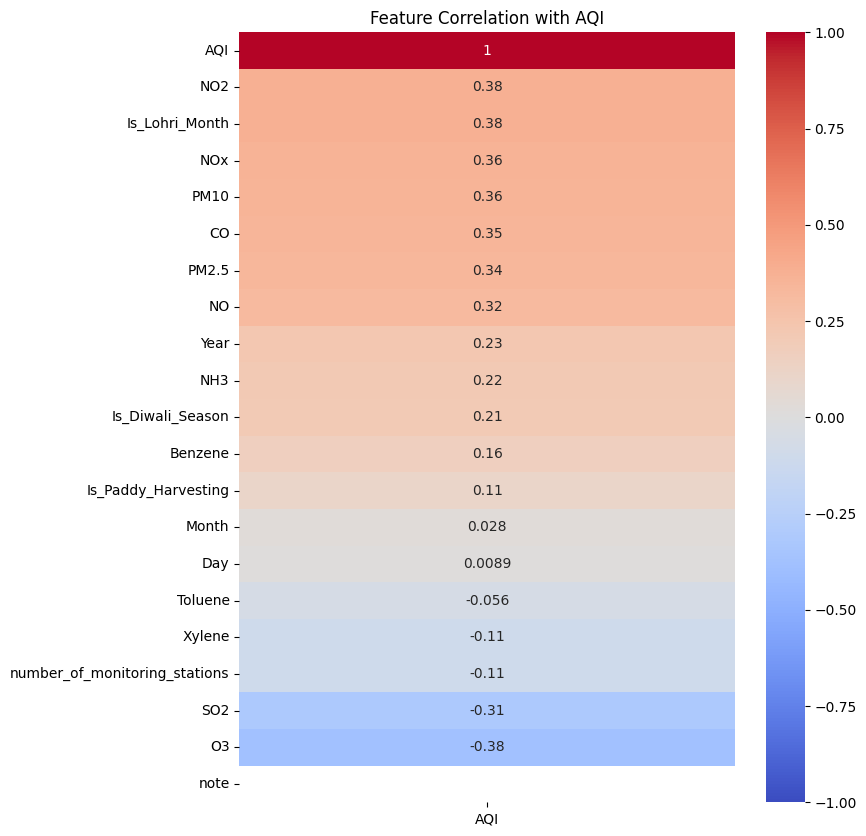


--- Feature Reduction Complete ---
Original number of columns: 29
Final number of useful columns: 17
Columns kept for Machine Learning: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'number_of_monitoring_stations', 'Year', 'Is_Lohri_Month', 'Is_Diwali_Season', 'Is_Paddy_Harvesting']

Files 'X_features.csv' and 'y_target.csv' saved successfully!


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#sorted database
df = pd.read_csv('chandigarh_temporal_features.csv')

#Machine learning algorithms crash if they see words or dates, they are removed here to create a purely mathematical dataset.
#Drop Non-Numeric Columns

#ensuring the 'AQI' column (target) is numeric, coercing errors
df['AQI'] = pd.to_numeric(df['AQI'], errors='coerce')

# Identifying all object (string) or category columns that are not 'AQI'
# non-numeric columns that should be dropped.
non_numeric_cols_to_drop = df.select_dtypes(include=['object', 'category']).columns.tolist()

# drop specific columns, so that they are covered
explicit_cols_to_check = ['City', 'Date', 'Season', 'Weekday']
for col in explicit_cols_to_check:
    if col in df.columns and col not in non_numeric_cols_to_drop:
        non_numeric_cols_to_drop.append(col)

# Drop identified non-numeric columns
df_numeric = df.drop(columns=non_numeric_cols_to_drop, errors='ignore')

# 3. Cleaning accidental missing values
# We cannot train a model if the target (AQI) is missing.
df_numeric = df_numeric.dropna(subset=['AQI'])
# Fill any other accidental blank cells with the median number of that column
# By this point, df_numeric should only contain numeric columns suitable for median calculation.
df_numeric = df_numeric.fillna(df_numeric.median())

# 4. Calculate Correlation
# This math checks how strongly every single column is linked to the AQI score.
# 1.0 means perfectly linked, 0.0 means no connection at all.
correlation = df_numeric.corr()

# Visualize the correlation specifically for AQI to see what matters most
plt.figure(figsize=(8, 10))
sns.heatmap(correlation[['AQI']].sort_values(by='AQI', ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature Correlation with AQI')
plt.show()

# 5. Feature Reduction (Dropping the useless clues)
# We tell the computer to only keep features that have at least a 0.05 correlation
# (either positive or negative) with the AQI. If a column scores 0.01, it is useless and gets dropped.
useful_columns = correlation[abs(correlation['AQI']) > 0.05].index
df_final = df_numeric[useful_columns]

# 6. Define X (The Clues) and y (The Answer Key)
X = df_final.drop(columns=['AQI']) # X is everything EXCEPT the AQI
y = df_final['AQI']                # y is ONLY the AQI

print("\n--- Feature Reduction Complete ---")
print(f"Original number of columns: {df.shape[1]}")
print(f"Final number of useful columns: {X.shape[1]}")
print("Columns kept for Machine Learning:", X.columns.tolist())

# 7. Export the final ML-ready datasets for Person 2 and Person 3
X.to_csv('X_features.csv', index=False)
y.to_csv('y_target.csv', index=False)
print("\nFiles 'X_features.csv' and 'y_target.csv' saved successfully!")